In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

data_path = r"C:\Users\main\Desktop\Projects\Retail Demand Forecasting"


df = pd.read_csv(
    data_path + r"\outputs\retail_demand_forecasting_featured.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset Shape: (198, 25)


,Date,Store_ID,Product_ID,Product_Category,Units_Sold,Unit_Price_NPR,Discount_Pct,Promotion,Day_of_Week,Is_Holiday,...,Weekend,Day,Day_of_Week_Number,Is_Weekend,Week_of_Year,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14,Rolling_Mean_7,Rolling_Mean_14
0,2025-01-01,ST-01,SKU-1001,Beverages,46.0,116.88,10.0,Yes,Wednesday,0.0,...,0,1,2,0,1,NaN,NaN,NaN,NaN,NaN
1,2025-01-02,ST-01,SKU-1001,Beverages,51.0,121.07,0.0,No,Thursday,0.0,...,0,2,3,0,1,46.0,NaN,NaN,NaN,NaN
2,2025-01-03,ST-01,SKU-1001,Beverages,46.0,119.51,10.0,Yes,Friday,0.0,...,0,3,4,0,1,51.0,NaN,NaN,NaN,NaN
3,2025-01-04,ST-01,SKU-1001,Beverages,42.0,121.15,0.0,No,Saturday,0.0,...,1,4,5,1,1,46.0,NaN,NaN,47.666667,NaN
4,2025-01-05,ST-01,SKU-1001,Beverages,45.0,124.30,0.0,No,Sunday,1.0,...,1,5,6,1,1,42.0,NaN,NaN,46.250000,NaN


In [2]:
# Target variable
target = "Units_Sold"

# Input features
features = [
    "Unit_Price_NPR",
    "Discount_Pct",
    "Promotion",
    "Day_of_Week",
    "Is_Holiday",
    "Inventory_Level",
    "Weather",
    "Year",
    "Month",
    "Day",
    "Day_of_Week_Number",
    "Is_Weekend",
    "Week_of_Year",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Rolling_Mean_7",
    "Rolling_Mean_14"
]

# Separate input and target
X = df[features].copy()
y = df[target].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (198, 18)
Target shape: (198,)


In [3]:
# Find chronological cutoff date
split_index = int(len(df) * 0.80)
split_date = df.loc[split_index, "Date"]

# Training period: dates before cutoff
train_mask = df["Date"] < split_date

# Testing period: cutoff date onwards
test_mask = df["Date"] >= split_date

# Separate training and testing data
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Remove rows with missing target values
train_valid = y_train.notna()
test_valid = y_test.notna()

X_train = X_train.loc[train_valid]
y_train = y_train.loc[train_valid]

X_test = X_test.loc[test_valid]
y_test = y_test.loc[test_valid]

print("Split Date:", split_date)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Period:")
print(df.loc[train_mask, "Date"].min(), "to",
      df.loc[train_mask, "Date"].max())

print("\nTesting Period:")
print(df.loc[test_mask, "Date"].min(), "to",
      df.loc[test_mask, "Date"].max())

Split Date: 2025-07-07 00:00:00

Training Data Shape: (153, 18)
Testing Data Shape: (39, 18)

Training Period:
2025-01-01 00:00:00 to 2025-07-06 00:00:00

Testing Period:
2025-07-07 00:00:00 to 2025-12-07 00:00:00


In [4]:
# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing prepared successfully!")

Numerical features: ['Unit_Price_NPR', 'Discount_Pct', 'Is_Holiday', 'Inventory_Level', 'Year', 'Month', 'Day', 'Day_of_Week_Number', 'Is_Weekend', 'Week_of_Year', 'Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14', 'Rolling_Mean_7', 'Rolling_Mean_14']

Categorical features: ['Promotion', 'Day_of_Week', 'Weather']

Preprocessing prepared successfully!


C:\Users\main\AppData\Local\Temp\ipykernel_640\3580825321.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [5]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=2,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

print("Models created successfully!")

Models created successfully!


In [7]:
trained_models = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    print(f"{name} trained successfully!")

print("\nAll models trained!")

Linear Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!

All models trained!


In [8]:
results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    wape = (
        np.sum(np.abs(y_test.to_numpy() - y_pred))
        / np.sum(np.abs(y_test.to_numpy()))
    ) * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE"
).reset_index(drop=True)

results_df

,Model,MAE,RMSE,WAPE (%)
0,Gradient Boosting,7.742010,9.288301,16.562720
1,Random Forest,9.826246,18.316767,21.021590
2,Linear Regression,75.986660,118.283267,162.560599


In [9]:
# Naive baseline: yesterday's sales
baseline_predictions = X_test["Sales_Lag_1"]

# Only evaluate rows where yesterday's sales are available
baseline_valid = baseline_predictions.notna()

baseline_actual = y_test.loc[baseline_valid]
baseline_pred = baseline_predictions.loc[baseline_valid]

baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(baseline_actual, baseline_pred)
)

baseline_wape = (
    np.sum(np.abs(baseline_actual.to_numpy() -
                  baseline_pred.to_numpy()))
    / np.sum(np.abs(baseline_actual.to_numpy()))
) * 100

baseline_result = pd.DataFrame([{
    "Model": "Naive Baseline (Yesterday's Sales)",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "WAPE (%)": baseline_wape
}])

print("Baseline performance:")
baseline_result

Baseline performance:


,Model,MAE,RMSE,WAPE (%)
0,Naive Baseline (Yesterday's Sales),8.526316,10.172202,18.294749


In [10]:
all_results = pd.concat(
    [results_df, baseline_result],
    ignore_index=True
)

all_results.sort_values(
    by="MAE"
).reset_index(drop=True)

,Model,MAE,RMSE,WAPE (%)
0,Gradient Boosting,7.742010,9.288301,16.562720
1,Naive Baseline (Yesterday's Sales),8.526316,10.172202,18.294749
2,Random Forest,9.826246,18.316767,21.021590
3,Linear Regression,75.986660,118.283267,162.560599


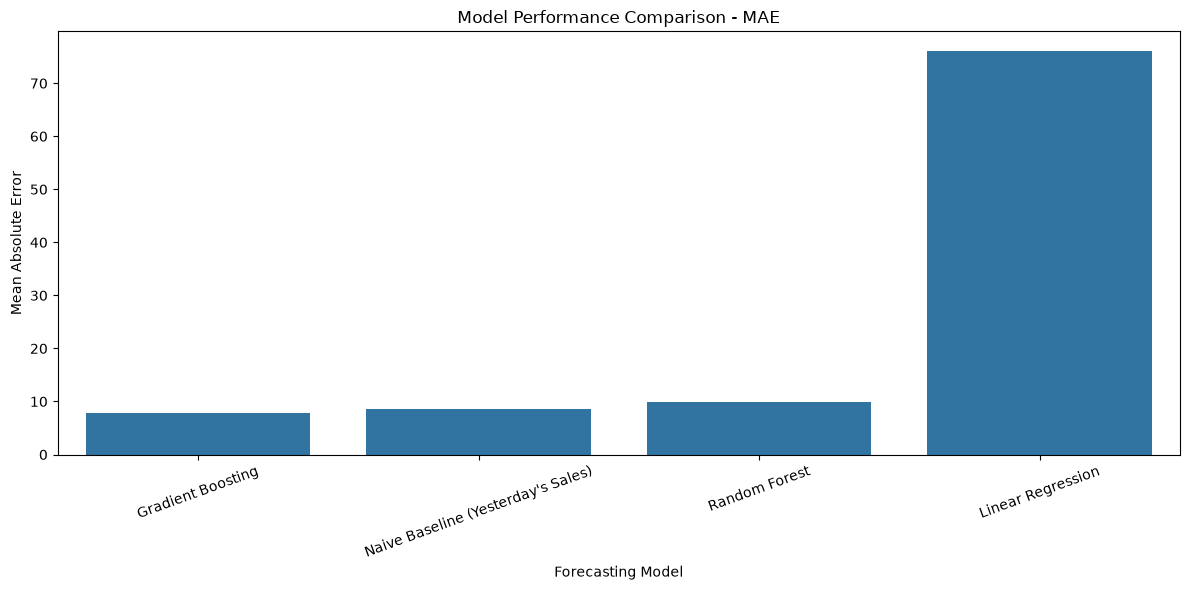

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results.sort_values("MAE"),
    x="Model",
    y="MAE"
)

plt.title("Model Performance Comparison - MAE")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=20)
plt.tight_layout()

eda_path = data_path + r"\outputs\eda"
os.makedirs(eda_path, exist_ok=True)

plt.savefig(
    eda_path + r"\11_model_comparison_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

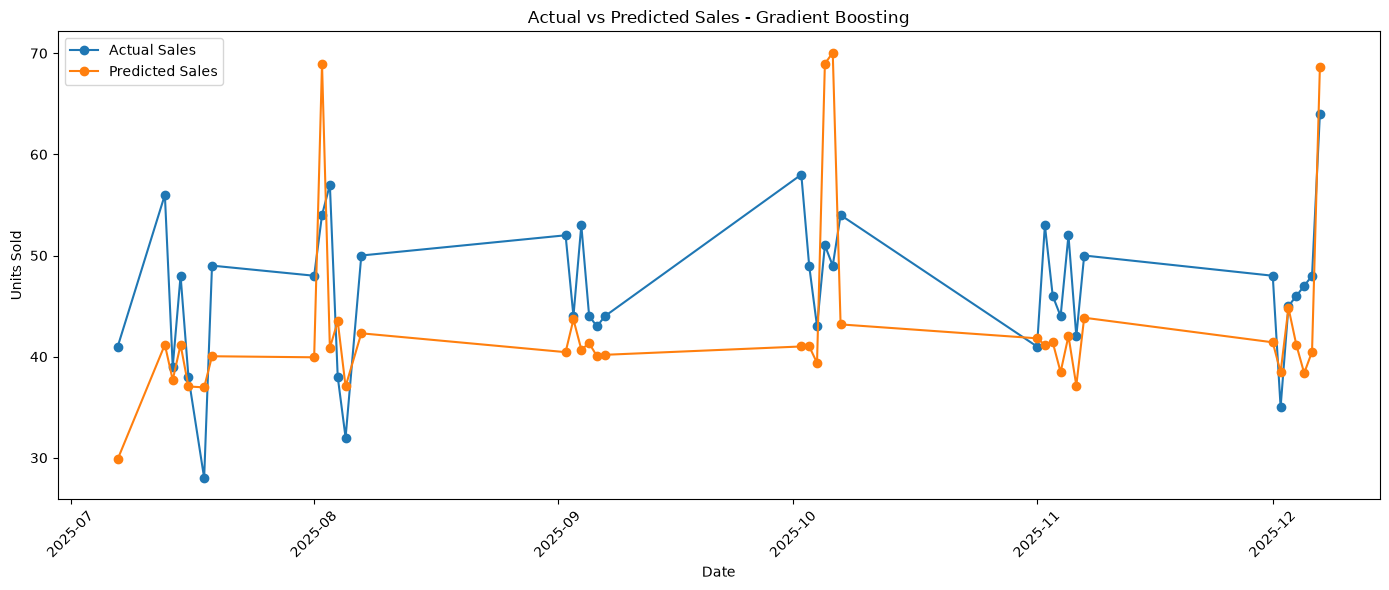

In [12]:
# Select the model with the lowest MAE
best_model_name = results_df.iloc[0]["Model"]

best_predictions = predictions[best_model_name]

comparison_df = pd.DataFrame({
    "Date": df.loc[X_test.index, "Date"].values,
    "Actual Sales": y_test.values,
    "Predicted Sales": best_predictions
})

comparison_df = comparison_df.sort_values("Date")

plt.figure(figsize=(14, 6))

plt.plot(
    comparison_df["Date"],
    comparison_df["Actual Sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    comparison_df["Date"],
    comparison_df["Predicted Sales"],
    marker="o",
    label="Predicted Sales"
)

plt.title(f"Actual vs Predicted Sales - {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    eda_path + r"\12_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
from sklearn.base import clone

In [14]:
trained_models = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    print(f"{name} trained successfully!")

print("\nAll models trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!

All models trained successfully!


In [15]:
output_path = data_path + r"\outputs"

all_results.to_csv(
    output_path + r"\model_evaluation_results.csv",
    index=False
)

comparison_df.to_csv(
    output_path + r"\actual_vs_predicted.csv",
    index=False
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!
